# 16 — Diagnóstico del primer entrenamiento y diseño de uno holístico

## Pregunta y alcance

El cuaderno 15 encontró la mejor forma de predecir **con lo que había**: la combinación SARIMAX + LightGBM,
que acertó 2026, un año que no había visto, a corto y mediano plazo. Este cuaderno pregunta si el
**entrenamiento** que produjo ese resultado es lo bastante amplio para responder el porqué de los picos, y no
solo para seguir el nivel de la demanda. El diagnóstico encontró cinco limitaciones en las variables con que se
entrenó:

1. **Aseguradoras.** Solo se medía Nueva EPS, como si fuera la única, y no el estado de las demás.
2. **Clima.** Entraron niveles (temperatura, humedad, lluvia, radiación, viento) y faltaron la duración de las
   rachas, los cambios bruscos, las horas de sol y la nubosidad.
3. **Salud.** Entró la IRA y unos pocos eventos de vigilancia, no las enfermedades más frecuentes de la ciudad
   cruzadas con clima, fiestas, vacaciones y calendario escolar.
4. **Fenómenos.** Solo se marcó la COVID. El Niño y La Niña, los sismos y las epidemias no estaban como estados.
5. **Evaluación.** El periodo de prueba es corto, se usó para elegir entre unos 20 diseños y el entrenamiento
   resultó demasiado específico de ese año.

El primer entrenamiento optimizó lo que ya se medía y perdió la vista general. El cuaderno explica la
combinación y por qué su respuesta es confiable, mide cada limitación con datos, inventaría las fuentes que se
pueden sumar, estima cuánto contexto soporta el modelo antes de sobreajustarse, describe el método de rejilla
con que se afinaron los árboles y propone un diseño de entrenamiento holístico y escalable.

In [1]:
import sys, pathlib, warnings, json
RAIZ = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "CLAUDE.md").exists())
sys.path.insert(0, str(RAIZ / "notebooks")); sys.path.insert(0, str(RAIZ)); warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from matplotlib import pyplot as plt
import pronostico as pr

AZUL, NARANJA, AQUA, AMARILLO, MAGENTA, VERDE, VIOLETA, ROJO = (
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948")
TINTA, TINTA2, MUDO, SUP = "#0b0b0b", "#52514e", "#898781", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SUP, "axes.facecolor": SUP, "axes.spines.top": False,
    "axes.spines.right": False, "axes.edgecolor": MUDO, "axes.grid": True, "grid.color": "#e6e5e1",
    "grid.linewidth": .6, "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlecolor": TINTA, "font.size": 10,
    "legend.frameon": False})
MESES = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]

def tabla(P, vara="calendario"):
    _, U = pr.leer(["control"], exp="e0", vara=vara)
    _, T = pr.metricas(P, U)
    return T[["acierta sube/baja %", "BSS sube %", "BSS pico %", "cob80 %", "MAPE %"]]

---
# 1. La combinación SARIMAX + LightGBM

## Qué aporta cada parte

| | **SARIMAX** | **LightGBM** |
|---|---|---|
| Familia | Serie de tiempo estadística | Ensamble de árboles de decisión con refuerzo (*gradient boosting*) |
| Cómo funciona | Mañana se parece a hoy, corregido por el día de la semana, el calendario y la época del año. Se **actualiza cada día** con lo que acaba de pasar | Hace cientos de preguntas en cadena (¿es lunes?, ¿es después de festivo?, ¿la semana pasada estuvo alta?), y cada árbol corrige los errores del anterior |
| Fortaleza | **Seguir los cambios de nivel** (los escalones de Nueva EPS) y dar **rangos honestos** | **Combinaciones de factores** que una fórmula lineal no ve, sobre todo en los meses estables |
| Debilidad | Es lineal: no capta interacciones | Se **confía de más** (rangos estrechos) y se adapta lento a un escalón nuevo |

La combinación promedia, cuantil a cuantil, las dos distribuciones: la mediana con la mediana, el 10 % con el
10 %, y así con todos. El resultado es una sola predicción con su rango.

## Por qué los dos modelos son compatibles: se equivocan en momentos distintos

Correlación de los errores SARIMAX-LightGBM: 0.85
Días en que uno se equivoca hacia arriba y el otro hacia abajo: 21%


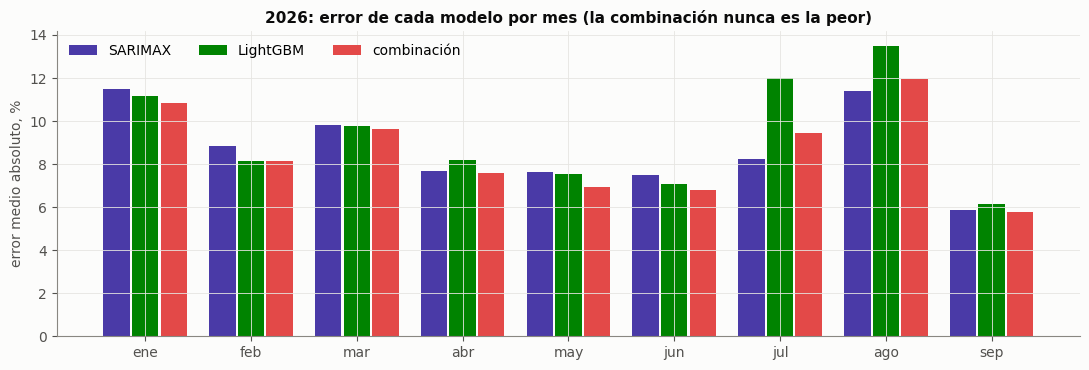

,acierta sube/baja %,BSS sube %,BSS pico %,cob80 %,MAPE %
modelo,,,,,
SARIMAX + LightGBM,69.4,21.1,16.5,80.3,8.9
LightGBM,67.8,15.9,11.4,71.2,9.8
SARIMAX,66.8,18.8,13.3,85.4,9.0


In [2]:
P, _ = pr.leer(["sarimax", "lightgbm", "comb_sarimax_lightgbm"], exp="e1"); P = P[P.origen >= "2025-12-31"].dropna(subset=["real"])
w = P.pivot_table(index=["origen", "h", "fecha"], columns="modelo", values="q50")
real = P.drop_duplicates(["origen", "h"]).set_index(["origen", "h", "fecha"])["real"]
err = np.log(w.div(real, axis=0)) * 100
print(f"Correlación de los errores SARIMAX-LightGBM: {err.sarimax.corr(err.lightgbm):.2f}")
print(f"Días en que uno se equivoca hacia arriba y el otro hacia abajo: {(np.sign(err.sarimax) != np.sign(err.lightgbm)).mean():.0%}")
m = err.abs().reset_index(); m["mes"] = m.fecha.dt.month
porm = m.groupby("mes")[["sarimax", "lightgbm", "comb_sarimax_lightgbm"]].mean()
fig, ax = plt.subplots(figsize=(11, 3.8)); x = np.arange(len(porm))
for j, (c, col, n) in enumerate([("sarimax", VIOLETA, "SARIMAX"), ("lightgbm", VERDE, "LightGBM"), ("comb_sarimax_lightgbm", ROJO, "combinación")]):
    ax.bar(x + (j - 1) * .27, porm[c], width=.25, color=col, label=n)
ax.set_xticks(x, [MESES[i - 1] for i in porm.index]); ax.set_ylabel("error medio absoluto, %")
ax.set_title("2026: error de cada modelo por mes (la combinación nunca es la peor)"); ax.legend(ncol=3); plt.tight_layout(); plt.show()
T = tabla(P); T.index = T.index.map({"sarimax": "SARIMAX", "lightgbm": "LightGBM", "comb_sarimax_lightgbm": "SARIMAX + LightGBM"}); T.round(1)

**Lectura.** Los dos modelos se equivocan de forma parecida (correlación de 0,85) pero no igual.

- El 21 % de los días uno queda por encima de lo real y el otro por debajo, y al promediarlos el error se cancela.
- **LightGBM falla más después de un escalón de Nueva EPS** (julio-agosto, 12-13 %), donde SARIMAX se adapta en días, y SARIMAX falla un poco más en los meses tranquilos.
- **La combinación nunca es la peor en ningún mes** y en 2026 es la mejor en casi todo: acierta el 69,4 % de las veces, mejora la probabilidad en un 21,1 % y cumple el rango del 80 % el 80,3 % de las veces. No se sobreconfía como LightGBM ni se muestra tan prudente como SARIMAX.

La compatibilidad se explica por la familia de cada modelo: una fórmula que sigue el nivel día a día y un conjunto de reglas que capta combinaciones tienen aciertos y fallos en lugares distintos, que es la situación en la que combinar pronósticos funciona. La cautela es que estas cifras corresponden a 2026, el año con el que se eligió.

---
# 2. Selección sobre 2026 y comprobación en 2025

Dos cosas que suenan parecido deben separarse: la fuga de datos y la selección mirando la prueba.

**(a) Fuga de datos: no hubo.** Cada predicción de 2026 se hizo con **origen rodante**:
- en el día *o*, el modelo solo conocía el triage y el contexto hasta *o*, y predecía de *o*+1 a *o*+7;
- cada 7 días se reentrenaba con todo lo anterior.

El modelo nunca vio el día que predecía, y el código lo garantiza por construcción (`notebooks/pronostico.py`).

**(b) Selección mirando la prueba: sí ocurrió.** Sobre el mismo 2026 se compararon unos 20 diseños:
- los experimentos E0 a E3;
- el jerárquico, con suma y con cópula;
- 42 modelos de LazyPredict;
- 3 árboles afinados;
- 2 combinaciones.

Cada diseño estaba preregistrado, pero elegir el mejor entre 20 con el mismo año convierte a 2026 en un
conjunto de *validación* y no de prueba: el mejor de 20 siempre luce algo mejor de lo que es. La comprobación
consiste en aplicar la misma combinación a **2025**, un año con el que no se eligió nada.

In [3]:
P0, _ = pr.leer(["sarimax", "lightgbm"], exp="e0"); P0 = P0[P0.origen < "2025-12-31"]
g = P0.groupby(["origen", "h", "fecha"]); c = g[pr.QCOL].mean().reset_index(); c["real"] = g.real.first().values
c["modelo"] = "comb_sarimax_lightgbm"; c = c[g.size().values == 2]
T25_e0 = tabla(pd.concat([P0, c])).assign(entrenamiento="2022-2024 (E0)")
partes = [T25_e0]
car = pr.SALIDA / "e1_2025"
if (car / "sarimax.parquet").exists() and (car / "lightgbm.parquet").exists():
    P1, _ = pr.leer(["sarimax", "lightgbm"], exp="e1_2025")
    g = P1.groupby(["origen", "h", "fecha"]); c = g[pr.QCOL].mean().reset_index(); c["real"] = g.real.first().values
    c["modelo"] = "comb_sarimax_lightgbm"; c = c[g.size().values == 2]
    partes.append(tabla(pd.concat([P1, c])).assign(entrenamiento="2020-2024 (como E1)"))
P26, _ = pr.leer(["sarimax", "lightgbm", "comb_sarimax_lightgbm"], exp="e1"); P26 = P26[P26.origen >= "2025-12-31"]
partes.append(tabla(P26).assign(entrenamiento="2020-2025 (E1) · 2026"))
R = pd.concat(partes).reset_index().rename(columns={"index": "modelo"})
R["año evaluado"] = np.where(R.entrenamiento.str.contains("2026"), "2026", "2025")
R.set_index(["año evaluado", "entrenamiento", "modelo"]).round(1)

acierta sube/baja %  \
año evaluado entrenamiento         modelo                                       
2025         2022-2024 (E0)        comb_sarimax_lightgbm                 57.6   
                                   lightgbm                              53.0   
                                   sarimax                               60.1   
             2020-2024 (como E1)   comb_sarimax_lightgbm                 59.9   
                                   lightgbm                              59.7   
                                   sarimax                               58.4   
2026         2020-2025 (E1) · 2026 comb_sarimax_lightgbm                 69.4   
                                   lightgbm                              67.8   
                                   sarimax                               66.8   

                                                          BSS sube %  \
año evaluado entrenamiento         modelo                              
2025         2022-2024 (E0)        comb_sarimax_lightgbm        -2.8   
                                   lightgbm                    -17.0   
                                   sarimax                       2.8   
             2020-2024 (como E1)   comb_sarimax_lightgbm         5.9   
                                   lightgbm                     -2.4   
                                   sarimax                       4.0   
2026         2020-2025 (E1) · 2026 comb_sarimax_lightgbm        21.1   
                                   lightgbm                     15.9   
                                   sarimax                      18.8   

                                                          BSS pico %  cob80 %  \
año evaluado entrenamiento         modelo                                       
2025         2022-2024 (E0)        comb_sarimax_lightgbm        -2.0     70.2   
                                   lightgbm                    -17.6     60.9   
                                   sarimax                      -3.7     76.3   
             2020-2024 (como E1)   comb_sarimax_lightgbm         4.3     78.0   
                                   lightgbm                      1.6     67.7   
                                   sarimax                      -3.7     84.1   
2026         2020-2025 (E1) · 2026 comb_sarimax_lightgbm        16.5     80.3   
                                   lightgbm                     11.4     71.2   
                                   sarimax                      13.3     85.4   

                                                          MAPE %  
año evaluado entrenamiento         modelo                         
2025         2022-2024 (E0)        comb_sarimax_lightgbm     9.4  
                                   lightgbm                 10.7  
                                   sarimax                   9.0  
             2020-2024 (como E1)   comb_sarimax_lightgbm     8.6  
                                   lightgbm                  9.3  
                                   sarimax                   8.8  
2026         2020-2025 (E1) · 2026 comb_sarimax_lightgbm     8.9  
                                   lightgbm                  9.8  
                                   sarimax                   9.0

**Lectura.** Elegir con 2026 sí infló el resultado de ese año, aunque no hubo fuga de datos.

- El origen rodante garantiza que cada predicción usó solo el pasado.
- Con la misma configuración (entrenando desde 2020) aplicada a **2025**, la combinación acierta el **59,9 %** y mejora la probabilidad un **5,9 %**, frente a 69,4 % y 21,1 % en 2026. SARIMAX obtiene 58,4 % y 4,0 %, y LightGBM 59,7 % y −2,4 %.
- **El orden se repite:** la combinación vuelve a ser la mejor en probabilidad y en rango (78 %), con un error del 8,6 %. Frente a LightGBM es significativamente mejor (Brier −20, IC [−30, −10]) y frente a SARIMAX es un empate. La combinación no se eligió por suerte.
- **La magnitud no se repite.** El 69 % de 2026 es propio de un año con escalones grandes de Nueva EPS, que premian a los modelos que siguen el nivel.
- La fila con entrenamiento 2022-2024 muestra además que con entrenamiento solo de 2022-2024 la combinación no supera a SARIMAX en 2025 (57,6 % frente a 60,1 %, mejora de la probabilidad de −2,8 % frente a +2,8 %): las probabilidades apenas rebasan la tasa base.

La expectativa razonable para un año cualquiera es de un 60 % de acierto con una mejora pequeña de la probabilidad (de 4 a 6 %). Eso es lo que se logra con calendario e historia. Explicar el porqué exige mejores variables, que es lo que motiva el resto del cuaderno. Este análisis no puede separar cuánto de la diferencia entre 2025 y 2026 se debe a los años de entrenamiento y cuánto a que 2026 favorecía el seguimiento del nivel.

**El seguimiento del nivel como segunda fuente de ventaja.** En el cuaderno 15 (sección 5.4) se mostró que buena
parte del 65-70 % de acierto en 2026 provenía de seguir los escalones de Nueva EPS más rápido que el control.
Con la vara justa (un control que también reacciona rápido), la cifra de anticipar el día baja a 60-64 %. Reaccionar
bien a lo que ya está ocurriendo tiene valor, pero no equivale a explicar por qué va a ocurrir, que es el objetivo
del proyecto.

---
# 3. Lo que el entrenamiento veía y lo que no

## 3.1 Aseguradoras: el modelo miraba a una sola

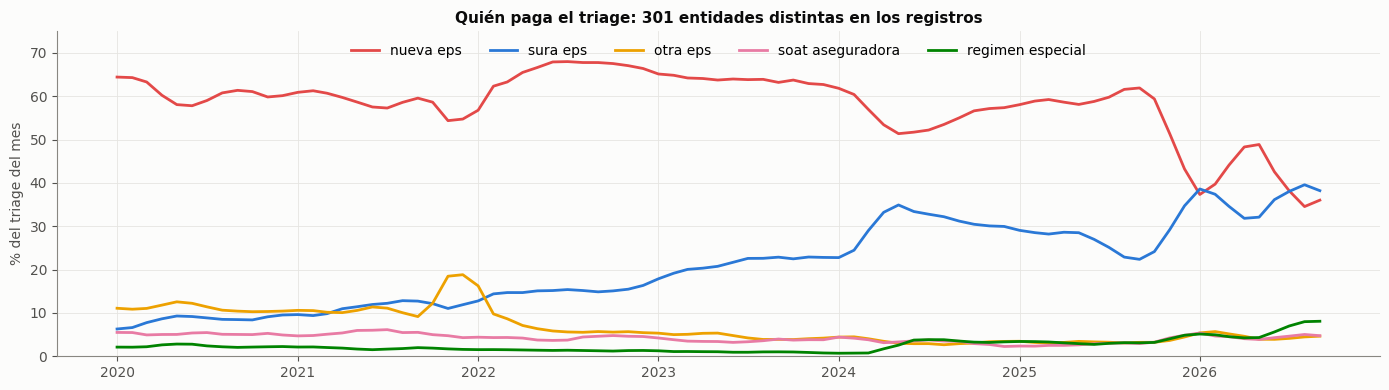

grupo,nueva_eps,sura_eps,otra_eps,regimen_especial,soat_aseguradora
mes,,,,,
2020,61.3,8.1,11.0,2.3,5.3
2021,57.6,11.3,13.2,1.8,5.2
2022,66.1,15.0,6.8,1.4,4.3
2023,63.9,21.4,4.6,1.0,3.7
2024,55.4,30.7,3.3,2.6,3.4
2025,58.0,27.0,3.3,3.3,3.0
2026,41.7,36.0,4.6,5.7,4.5


In [4]:
from extraccion.entidades import clasificar
te = pd.read_parquet(RAIZ / "salidas/triage_entidad.parquet", columns=["dia", "entidad", "n"])
te["mes"] = pd.to_datetime(te.dia).dt.to_period("M").dt.to_timestamp(); te = clasificar(te)
M = te.pivot_table(index="mes", columns="grupo", values="n", aggfunc="sum").fillna(0)
pesos = M.div(M.sum(axis=1), axis=0) * 100
fig, ax = plt.subplots(figsize=(14, 4))
for gname, col in [("nueva_eps", ROJO), ("sura_eps", AZUL), ("otra_eps", AMARILLO), ("soat_aseguradora", MAGENTA), ("regimen_especial", VERDE)]:
    ax.plot(pesos.index, pesos[gname].rolling(3, center=True, min_periods=1).mean(), color=col, lw=2, label=gname.replace("_", " "))
ax.set_ylabel("% del triage del mes"); ax.legend(ncol=5, loc="upper center"); ax.set_ylim(0, 75)
ax.set_title(f"Quién paga el triage: {te.entidad.nunique()} entidades distintas en los registros"); plt.tight_layout(); plt.show()
anual = (M.groupby(M.index.year).sum().T / M.groupby(M.index.year).sum().sum(axis=1)).T * 100
anual[["nueva_eps", "sura_eps", "otra_eps", "regimen_especial", "soat_aseguradora"]].round(1)

**Lectura.** El modelo miraba a una sola aseguradora y la composición de la demanda cambió.

- **SURA EPS pasó del 8 % del triage (2020) al 36 % (2026).** Nueva EPS bajó del 61 % al 42 %.
- **Los pacientes no desaparecieron: se movieron de aseguradora.** Entre 2025 y 2026 el resto de aseguradoras subió de 84 a 100 triages al día mientras Nueva EPS caía.
- Hay **301 entidades distintas** en los registros, agrupadas en 14 grupos.

Lo que falta no son datos internos sino el estado externo de cada EPS: cuántos afiliados tiene en Manizales, si está intervenida, cuántas quejas recibe y cuánto le paga al hospital. Las cuatro cosas existen como fuentes públicas (sección 4.2).

## 3.2 Enfermedades de Manizales: hay mucho más que IRA

In [5]:
e = pd.read_csv(RAIZ / "calendarios/vigilancia_sivigila_eventos.csv.gz")
e = e[(e.ambito == "manizales") & (e.variable == "casos_notificacion") & e.anio.between(2022, 2025)]
cen = pd.read_csv(RAIZ / "calendarios/vigilancia_sivigila_eventos_censo.csv").set_index("evento")["nombre"]
v = pd.read_csv(RAIZ / "calendarios/vigilancia_sivigila.csv.gz"); v = v[(v.ambito == "manizales") & v.anio.between(2022, 2025)]
filas = [{"evento": "995 consultas por IRA", "casos 2022-2025": v[(v.evento == 995) & (v.variable == "consultas_ira_total")].valor.sum()},
         {"evento": "998 EDA (diarrea)", "casos 2022-2025": v[(v.evento == 998) & (v.variable == "casos_eda_total")].valor.sum()}]
top = e.groupby("evento").valor.sum().sort_values(ascending=False).head(10)
filas += [{"evento": f"{k} {cen.get(k, '')}".strip(), "casos 2022-2025": val} for k, val in top.items()]
D = pd.DataFrame(filas); D["casos 2022-2025"] = D["casos 2022-2025"].astype(int)
D["¿entró al modelo?"] = ["sí (E2/E3)", "no: no hay 2026", "sí (E2)", "sí (E2)", "sí (E2)", "sí (E2)", "no", "no", "sí (E2)", "no", "no", "no"][:len(D)]
D

,evento,casos 2022-2025,¿entró al modelo?
0,995 consultas por IRA,248277,sí (E2/E3)
1,998 EDA (diarrea),82679,no: no hay 2026
2,300 AGRESIONES POR ANIMALES POTENCIALMENTE TRA...,5900,sí (E2)
3,875 VCM VIF VSX,5499,sí (E2)
4,356 INTENTO DE SUICIDIO,2812,sí (E2)
5,365 INTOXICACIONES (suma de 360-414),2237,sí (E2)
6,549 MORBILIDAD MATERNA EXTREMA,1854,no
7,370 INTOXICACION POR FARMACOS,1666,no
8,831 VARICELA INDIVIDUAL,963,sí (E2)
9,850 VIH/SIDA/MORTALIDAD POR SIDA,912,no


**Lectura.** Por volumen, la salud pública de Manizales son dos grandes y varias medianas.

- IRA (248.277 consultas en 2022-2025) y EDA (82.679 casos) son de otro orden de magnitud. Les siguen las agresiones por animales, la violencia de género, el intento de suicidio, las intoxicaciones, la morbilidad materna extrema y la varicela.
- Al modelo entraron la IRA y 5 eventos, pero **la EDA no**, porque sin una foto de Power BI no hay 2026, y **lo materno-perinatal tampoco**, aunque el hospital tiene un 12,6 % de triage obstétrico.
- Las familias con volumen para entrenar son la respiratoria (IRA, IRAG), la digestiva (EDA), las violencias y agresiones (eventos 875 y 300), la salud mental y las intoxicaciones (356 y 365) y la materno-perinatal (549).
- El dengue no aplica: no hay transmisión en Manizales por la altitud.

## 3.3 Clima: lo que entró y lo que no se había construido

El clima unificado tiene 69 columnas. Al modelo entraron **12 variables de nivel o anomalía**: temperatura
media, mínima y máxima, amplitud, humedad, lluvia de 7 y 30 días, radiación y su cambio, y viento. Todas
describen el estado del día o de la semana, y ninguna describe la **transición**: la hipótesis del proyecto es
que importa el cambio de régimen (empezó a llover después de una seca) y no el nivel, y una variable de nivel
promedia ese cambio y lo borra. El diseño propuesto incorpora las variables siguientes.

| Variable ausente | Cómo se construye | Fuente |
|---|---|---|
| **Días sin llover** y racha seca | días desde el último día con lluvia ≥ 1 mm (solo pluviómetro válido o acumulados) | `clima_unificado` |
| **Días de sol continuo** | racha de días con radiación u horas de sol sobre lo normal del mes | `clima_unificado` + Open-Meteo |
| **Horas de sol y nubosidad** | `sunshine_duration`, `cloud_cover` | Open-Meteo (también en pronóstico desde 2024) |
| **Punto de rocío y humedad absoluta** | `dew_point_2m` | Open-Meteo, NASA POWER |
| **Cambio brusco** (seco a lluvioso, cálido a frío) | diferencia entre la última semana y las 3 anteriores, contra lo normal | derivada |
| **Extremos** | días con lluvia > p90 o temperatura < p10 en la última semana | derivada |
| **Lo que se sabrá al predecir** | el **pronóstico** del clima de los próximos días, no el observado | Open-Meteo Previous Runs (desde 2024) |

Un barrido posterior de estas variables (2010-2024, 266 pruebas por desenlace, mes y año fijos, corrección de
Benjamini-Hochberg con q = 0,10) mostró dónde actúa el clima:

| Desenlace | Pruebas que sobreviven | Lectura |
|---|---|---|
| IRA de Manizales (2012-2024) | **53** (el azar daría unas 13) | un mes lluvioso, nublado, húmedo y con poco sol trae **+6-7 % de IRA a 1-5 semanas**; las horas de sol (−7 %) y el déficit de presión de vapor (−6,7 %) figuran entre las más fuertes |
| Triage total (2022-2024) | 36, con efectos de 1,5-2,4 % | efecto diluido: pesan la semana muy lluviosa reciente, las rachas secas y el calor del último mes |
| Ingresos respiratorios del hospital (2021-2024) | 0 | son ingresos (un tercio de lo que llega, unos 33 por semana) y no triage |

De ahí sale el diseño: la vía del clima hacia el hospital pasa por la IRA de la ciudad, y al modelo conviene
darle índices de estado y de cambio, más dos o tres rachas, y no 38 variables sueltas.

## 3.4 Fenómenos y catástrofes: cuántos hay de los que aprender

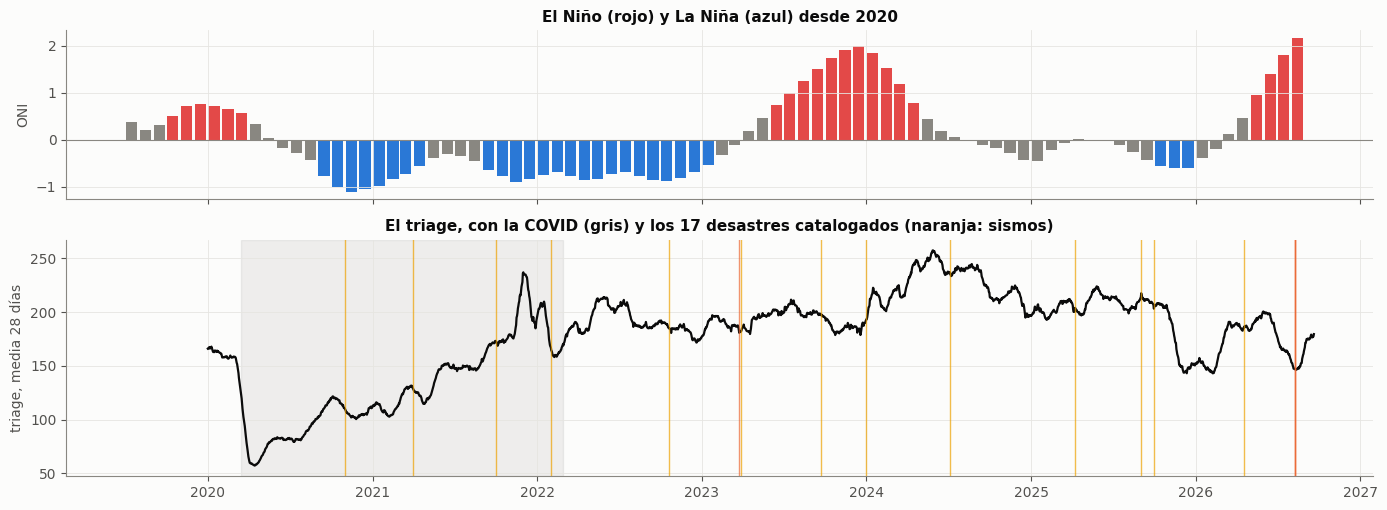

Episodios ENSO desde mediados de 2019:
            fase  meses
         neutral      3
         el_nino      6
         neutral      5
         la_nina      8
         neutral      4
         la_nina     17
         neutral      4
         el_nino     11
         neutral     24
el_nino_en_curso      4

Desastres catalogados 2020-2026: 17 ({'deslizamiento': 9, 'sismo': 4, 'actividad_volcanica': 1, 'vendaval': 1, 'incendio_forestal': 1, 'multiple': 1})


In [6]:
en = pd.read_csv(RAIZ / "calendarios/enso_oni.csv", parse_dates=["fecha"]); en = en[en.fecha >= "2019-07-01"]
pr.usar("e1"); y, _ = pr.cargar()
fig, axes = plt.subplots(2, 1, figsize=(14, 5.2), sharex=True, gridspec_kw={"height_ratios": [1, 1.4]})
axes[0].bar(en.fecha, en.oni, width=25, color=np.where(en.oni > 0.5, ROJO, np.where(en.oni < -0.5, AZUL, MUDO)))
axes[0].axhline(0, color=MUDO, lw=.8); axes[0].set_ylabel("ONI"); axes[0].set_title("El Niño (rojo) y La Niña (azul) desde 2020")
axes[1].plot(y.index, y.rolling(28, center=True, min_periods=14).mean(), color=TINTA, lw=1.6)
d = pd.read_csv(RAIZ / "calendarios/desastres_manizales_2020_2026.csv", parse_dates=["fecha_inicio"])
for _, r in d.iterrows(): axes[1].axvline(r.fecha_inicio, color=NARANJA if r.tipo_evento == "sismo" else AMARILLO, lw=1, alpha=.7)
axes[1].axvspan(pd.Timestamp("2020-03-15"), pd.Timestamp("2022-02-28"), color=MUDO, alpha=.12)
axes[1].set_ylabel("triage, media 28 días"); axes[1].set_title("El triage, con la COVID (gris) y los 17 desastres catalogados (naranja: sismos)")
plt.tight_layout(); plt.show()
fase = en.set_index("fecha").fase
ep = fase.groupby((fase != fase.shift()).cumsum()).agg(["first", "size"]).rename(columns={"first": "fase", "size": "meses"})
print("Episodios ENSO desde mediados de 2019:"); print(ep.to_string(index=False))
print(f"\nDesastres catalogados 2020-2026: {len(d)} ({d.tipo_evento.value_counts().to_dict()})")

**Lectura.** El límite más duro es de muestra y no de código.

- Desde 2020 hay unos **4 episodios ENSO**: La Niña 2020-21, La Niña 2021-23, El Niño 2023-24 y el El Niño fuerte en curso (JAS 2026 = +2,16). Hay **1 COVID** y **17 desastres catalogados**, la mayoría deslizamientos locales.
- Con 4 ejemplos un modelo no aprende el efecto de El Niño: memoriza lo que pasó en esos 4, que es sobreajuste.
- Lo que sí se puede hacer es marcar los fenómenos como **estados que duran meses** (régimen El Niño, La Niña o neutral; EPS intervenida; alerta hospitalaria) y usar la **historia larga del entorno** (SIVIGILA desde 2007, clima desde 1981) para aprender cómo afecta cada fenómeno a la ciudad, trasladando al hospital solo ese efecto ya aprendido.

---
# 4. Fuentes que se pueden sumar

El inventario sale de una revisión de fuentes en la web hecha en octubre de 2026, sumada al inventario del
repositorio (`calendarios/docs/FUENTES_EXTERNAS.md`, `FUENTES_VIGILANCIA.md`, `INVENTARIO.md`). La columna que
más pesa es **«¿se tiene al predecir?»**: un dato que llega 8 meses tarde sirve para entrenar, no para
pronosticar.

## 4.1 Salud (SIVIGILA y otras)

| Fuente | Qué da | Granularidad | ¿Se tiene al predecir? | Estado |
|---|---|---|---|---|
| **Microdatos SIVIGILA** (portalsivigila.ins.gov.co/Microdatos) | todos los eventos, caso a caso; IRA y EDA colectivas | semana × municipio, 2007-2025 | no: ~8 meses de retraso | en el repo (entrenar) |
| **Power BI del INS** (tableros 006 rutinaria y 995) | evento × semana × municipio; IRA con denominador | semana, Manizales | **sí: ~7 días** | en el repo, una sola foto: para tener histórico hay que congelarla cada semana |
| BES del INS | tablero departamental | semana, Caldas | sí: ~6 días | PDF |
| Boletines DTSC y Secretaría de Salud de Manizales | IRA, EDA y varicela por edad | semana o mes | tarde, en bloque | PDF |
| **Cubos SISPRO/RIPS** | **consultas, urgencias y hospitalización por diagnóstico CIE-10 y municipio** | mensual | no (meses) | requieren usuario de MinSalud |
| **Diagnósticos del propio hospital** (cuaderno 10) | respiratorio, infeccioso, trauma, embarazo, urinario… | diario, desde 2020 | **sí** | en el repo, `perfil_dx_diario` (local) |

## 4.2 Estado de **todas** las EPS

| Fuente | Qué da | Granularidad | ¿Se tiene al predecir? |
|---|---|---|---|
| **MinSalud, cifras de afiliación** | afiliados por EPS × municipio × régimen | mensual, desde 2016 (Tableau) | sí: 1 mes |
| **Supersalud, medidas especiales**, resoluciones y FENIX | intervenciones, vigilancia especial, liquidaciones, con fecha | por evento | sí |
| **Supersalud, PQRD** | quejas por EPS y motivo, tasa por cada 10.000 afiliados (barreras de acceso) | mensual, desde 2017 | sí: ~5 semanas |
| **ADRES, giro directo** | cuánto paga cada EPS a cada IPS (incluido el SES) | mensual, desde 2020 | por verificar |
| BDUA en datos.gov.co | foto de afiliados por EPS y municipio | foto mensual, **sin histórico** | sí, pero solo la foto vigente: el histórico exige guardarla cada mes |
| **El triage del propio hospital por asegurador** | peso y cambio de cada EPS en la demanda | diario, desde 2020 | **sí** |

**Monitoreo continuo de las EPS.** El diseño consiste en una captura mensual del zip de afiliación de
MinSalud, la foto de la BDUA, el Excel de medidas y el de PQRD, más una revisión de las resoluciones nuevas de
la Supersalud y de las noticias de la Alcaldía (el repositorio ya tiene una API para estas últimas). No se
encontró RSS ni API de la Supersalud.

## 4.3 Clima, fenómenos y otras señales

| Fuente | Qué da | ¿Se tiene al predecir? |
|---|---|---|
| **Open-Meteo Previous Runs** | **pronóstico** a 1-7 días: lluvia, temperatura, humedad, **horas de sol**, nubosidad | **sí**, desde ~2024 |
| Open-Meteo Historical Forecast / ERA5, NASA POWER, IDEAM | clima observado o de reanálisis | observado: hasta el día anterior |
| **NOAA ONI** | El Niño / La Niña (JAS 2026 = +2,16: El Niño fuerte) | sí: ~1 mes |
| USGS | sismos (27 de M ≥ 3 a menos de 100 km desde 2020) | sí: minutos |
| UNGRD | emergencias por municipio | no: ≥ 9 meses; muy ralo |
| Open-Meteo Air Quality, SISAIRE | PM2.5 y PM10 (con pronóstico desde 2022) | sí |
| Google Trends (API alfa) | búsquedas de síntomas | hay que pedir acceso |

---
# 5. Cuánto contexto soporta el modelo antes de sobreajustarse

El límite no lo pone la cantidad de variables sino la cantidad de **ejemplos independientes** de cada fenómeno.

- **Días.** De 2022 a 2025 hay ~1.400 días, pero los días seguidos se parecen (autocorrelación de 0,35).
  Equivalen a unos **670 días independientes**. Una regla prudente es pedir al menos 10-20 ejemplos
  independientes por cada parámetro que se estima. Para efectos diarios (clima de la semana, eventos),
  eso da **del orden de 30 a 60 parámetros** como techo.
- **Fenómenos raros.** Para El Niño, la COVID o un terremoto, el ejemplo no es un día sino **un
  episodio**. Desde 2020 hay unos **4 episodios ENSO**, **1 COVID** y **un puñado de sismos**. Con 4
  ejemplos no se aprende un efecto: el modelo memoriza qué pasó en esos 4. Eso es sobreajuste.
- **Lo que ya se midió en este proyecto:** al pasar de 28 a 36 entradas (E3) y a 77 (E2), la regresión y
  LightGBM **empeoraron** en 2026.

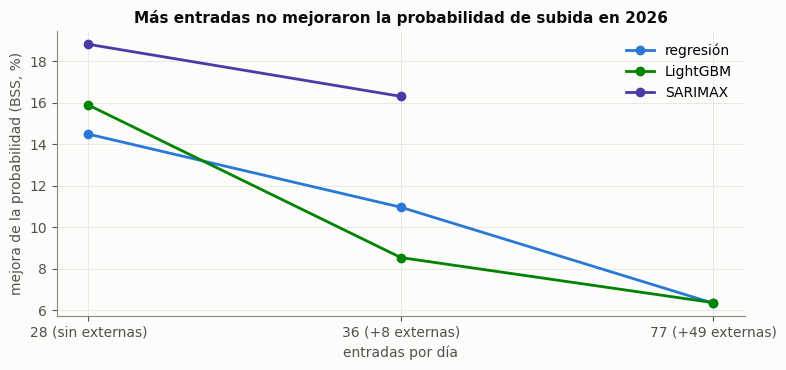

BSS sube %                   acierta %                 
modelo            glm_binneg lightgbm sarimax glm_binneg lightgbm sarimax
entradas                                                                 
28 (sin externas)       14.5     15.9    18.8       65.0     67.8    66.8
36 (+8 externas)        11.0      8.5    16.3       62.5     64.9    65.0
77 (+49 externas)        6.3      6.4     NaN       59.9     62.6     NaN

In [7]:
filas = []
for exp, n in [("e1", "28 (sin externas)"), ("e3", "36 (+8 externas)"), ("e2", "77 (+49 externas)")]:
    for m in ["glm_binneg", "lightgbm", "sarimax"]:
        f = pr.SALIDA / exp / f"{m}.parquet"
        if f.exists():
            P, _ = pr.leer([m], exp=exp); P = P[P.origen >= "2025-12-31"]
            t = tabla(P).iloc[0]; filas.append({"entradas": n, "modelo": m, "BSS sube %": t["BSS sube %"], "acierta %": t["acierta sube/baja %"]})
F = pd.DataFrame(filas)
fig, ax = plt.subplots(figsize=(8, 3.8))
for m, col in [("glm_binneg", AZUL), ("lightgbm", VERDE), ("sarimax", VIOLETA)]:
    g = F[F.modelo == m]; ax.plot(g.entradas, g["BSS sube %"], "-o", color=col, lw=2, label={"glm_binneg": "regresión", "lightgbm": "LightGBM", "sarimax": "SARIMAX"}[m])
ax.set_ylabel("mejora de la probabilidad (BSS, %)"); ax.set_xlabel("entradas por día"); ax.legend()
ax.set_title("Más entradas no mejoraron la probabilidad de subida en 2026"); plt.tight_layout(); plt.show()
F.pivot_table(index="entradas", columns="modelo", values=["acierta %", "BSS sube %"]).round(1)

**Lectura.** Las curvas confirman lo que anticipaba el conteo de ejemplos independientes: al pasar de 28 a 36
entradas (E3) y a 77 (E2), la regresión y LightGBM empeoraron en 2026, de modo que el contexto sumado en bruto no
ayudó con tan pocos ejemplos independientes.

**Cómo dar más contexto sin sobreajustar**

1. **Índices por familia en lugar de variables sueltas.** Un «índice de presión respiratoria» que resuma IRA
   total, IRA 0-4, IRAG y consultas, o un «estado del clima» que resuma temperatura, humedad, sol y lluvia. Al
   modelo entra una cifra por familia y el contexto completo sigue representado.
2. **Regímenes en lugar de episodios.** El Niño, La Niña, «EPS en crisis» o «temporada festiva» entran como
   **estados** que se repiten, y no como fechas únicas. Un estado con muchos días sí se puede aprender.
3. **Modelos que se frenan solos.** Regularización (Ridge o Lasso), árboles poco profundos, mínimo de ejemplos
   por hoja. La rejilla de la sección 6 eligió árboles de profundidad 2-3: los datos piden simplicidad.
4. **Agregar las familias de una en una** y conservar solo las que mejoran en un año de validación distinto del
   de prueba.
5. **Llevar cada contexto a la serie donde actúa.** El clima y la IRA mueven lo **respiratorio** del hospital
   (+10-14 %, cuaderno 13) y se diluyen en el total. Un modelo jerárquico **por tipo de consulta**
   (respiratorio, infeccioso, trauma, embarazo, otros), cada uno con su contexto, suma al final el total, y es
   la arquitectura que escala.

---
# 6. El método de rejilla

Un modelo tiene perillas que se fijan antes de entrenarlo: cuántos árboles, qué profundidad, qué velocidad de
aprendizaje. Se llaman **hiperparámetros**. El método de rejilla (*grid search*):
1. arma una **lista de valores** para cada perilla, por ejemplo profundidad 2, 3 o 4 y 200 o 500 árboles;
2. prueba **todas las combinaciones** (3 × 2 = 6 modelos);
3. mide cada uno con datos que no usó para entrenar y conserva el que menos se equivoca.

En el cuaderno 15 se afinaron XGBoost, GradientBoosting y LightGBM con una rejilla sobre 2024. La tabla es la
rejilla real de XGBoost (error medio del logaritmo en 2024; menos es mejor).

In [8]:
E = json.loads((pr.SALIDA / "e1" / "_afinado_xgboost_etapas.json").read_text(encoding="utf-8"))
R = pd.DataFrame(E["rejilla"]).sort_values("mae_log"); R["error medio %"] = (np.exp(R.mae_log) - 1) * 100
print("elegida:", E["elegida"]); R.round(4)

elegida: {'max_depth': 2, 'n_estimators': 500, 'learning_rate': 0.1}


,max_depth,n_estimators,learning_rate,mae_log,error medio %
0,2,500,0.10,0.0975,10.2459
1,3,500,0.10,0.1021,10.7440
2,3,500,0.03,0.1025,10.7960
3,4,500,0.03,0.1035,10.9072
4,3,200,0.10,0.1037,10.9223
5,2,200,0.10,0.1039,10.9474
6,4,500,0.10,0.1053,11.1020
7,4,200,0.10,0.1064,11.2259
8,2,500,0.03,0.1107,11.7037
9,4,200,0.03,0.1130,11.9640


**Tres reglas para que la rejilla no engañe**
1. **Se afina en un periodo y se prueba en otro.** Se afinó con 2024, se calibró con 2025 y se probó en 2026. Si
   se afina mirando la prueba, la rejilla «encuentra» la combinación que acierta por suerte.
2. **Pocas perillas y pocos valores.** Con 12 combinaciones el riesgo es bajo; con miles, alguna gana por azar.
   Para rejillas grandes conviene la búsqueda aleatoria o la bayesiana (por ejemplo, Optuna).
3. **Validación de origen rodante dentro del periodo de afinado**, nunca un corte al azar.

La rejilla eligió árboles **poco profundos** (2-3 niveles). Lo mejor de 2024 no fue lo mejor de 2026, porque 2026
fue otro régimen (el desplome de Nueva EPS). Afinar ayuda, pero no sustituye tener las variables correctas.

---
# 7. Diseño de un entrenamiento holístico y escalable

| Capa | Qué entra | Cómo, sin sobreajustar |
|---|---|---|
| **Red de salud** | **todas** las EPS: afiliados mensuales (MinSalud), medidas e intervenciones (Supersalud), quejas (PQRD), giros (ADRES), peso de cada EPS en el triage | un **índice de estrés de la red** más el estado de las 3-4 EPS grandes (Nueva EPS, SURA, Salud Total, Sanitas) |
| **Calendario y vida social** | festivos, puentes, quincena, vacaciones y horario escolar, Feria, fiestas, días especiales | como en el primer entrenamiento |
| **Clima completo** | nivel, **rachas** (días sin lluvia, días de sol), **transiciones**, horas de sol y nubosidad, **pronóstico** | índices de «estado del clima» y de «cambio brusco», con rezagos de 1 a 3 semanas |
| **Salud pública** | las 5-6 familias con volumen en Manizales: **IRA, EDA, violencias y agresiones, salud mental e intoxicaciones, materno-perinatal** | un índice por familia, con rezago de 1 semana (Power BI) |
| **Regímenes y fenómenos** | El Niño y La Niña, COVID, sismo fuerte, alerta hospitalaria, EPS intervenida | **estados** que se repiten, no fechas sueltas |
| **Estructura** | **jerárquico por tipo de consulta**: respiratorio, infeccioso, trauma, embarazo, resto | cada parte con su contexto; el total es la suma |

**Protocolo de evaluación, para no repetir la selección sobre la prueba**
1. **Afinar** con 2020-2024.
2. **Elegir** el diseño con 2025, y solo con 2025.
3. **Probar una sola vez** en 2026, sin cambiar nada después.
4. **Prueba prospectiva:** congelar el modelo y compararlo con octubre-diciembre de 2026, un periodo que hoy
   nadie conoce. Es la única prueba que no admite discusión.

Los regímenes y fenómenos se desarrollan en el cuaderno 20, el modelo jerárquico en el 21 y el catálogo de
variables con su validación en varios años en el 23.

## Conclusiones y límites

**Punto de partida.** La combinación SARIMAX + LightGBM es la mejor forma encontrada de predecir con calendario e historia. Es la mejor en dos años distintos y en 2025, el año con el que no se eligió nada, acierta cerca del 60 % con un rango honesto (78 %). En 2026 luce mejor (69 %) porque ese año favoreció a los modelos que siguen el nivel, y esa cifra no debe tomarse como expectativa.

**Diagnóstico del primer entrenamiento**

| Limitación | Qué mostró la medición | Dato |
|---|---|---|
| Solo se medía Nueva EPS | se confirma | SURA pasó de 8 % a 36 % del triage; falta el estado externo de todas |
| Clima sin contexto completo | se confirma | entraron 12 niveles; faltaban rachas, transiciones, horas de sol y pronóstico |
| Solo IRA | se confirma en parte | entraron IRA y 5 eventos; faltaban EDA y lo materno-perinatal |
| Fenómenos sin marcar | se confirma en parte | el ENSO entró como número y no como régimen; con 4 episodios no se aprende suelto |
| Selección sobre 2026 | se confirma sin fuga de datos | 69 % en 2026 frente a 60 % en 2025 |

**Diseño propuesto** (sección 7): panel externo de todas las EPS; clima completo con rachas, transiciones y pronóstico; las 5-6 familias de enfermedades como índices; regímenes en lugar de fechas sueltas; un modelo jerárquico por tipo de consulta, donde cada contexto actúa en su parte; y afinar en 2020-2024, elegir con 2025, probar una sola vez en 2026 y contrastar con un periodo prospectivo.

**Límites.** La muestra efectiva es de unos 670 días independientes, lo que deja espacio para decenas de parámetros y no para centenares, y casi ninguno para fenómenos que han ocurrido 4 veces. La salida es resumir por familias y por regímenes y no sumar variables sueltas. Además, el diagnóstico describe qué se omitió, pero no mide todavía cuánto mejoraría la predicción al incorporarlo: eso depende de cada familia y se evalúa en los cuadernos posteriores.